## What is the most optimal skill to learn for Data Analysts?

### Methodology
- Group skills to determine median salary and likelihood of being in posting
- Visualize Median Salary vs Percent Skill Demand
- (Optional) Determine if certain technologies are more prevalent

In [3]:
import ast 
import pandas as pd
import seaborn as sns
from datasets import load_dataset
import matplotlib.pyplot as plt

# Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()


# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [4]:
df_DA_US = df[
    (df['job_title_short'] == 'Data Analyst') &
    (df['job_country'] == 'United States')
].copy()

In [6]:
df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])

df_DA_US_exploded = df_DA_US.explode('job_skills')

df_DA_US_exploded[['salary_year_avg', 'job_skills']].head(5)

,salary_year_avg,job_skills
109,89000.0,python
109,89000.0,r
109,89000.0,alteryx
109,89000.0,tableau
180,90250.0,excel


In [11]:
df_DA_skills = df_DA_US_exploded.groupby('job_skills')['salary_year_avg'].agg(['count','median']).sort_values(by = 'count', ascending = False)

In [12]:
df_DA_skills = df_DA_skills.rename(columns = {'count': 'skill_count', 'median': 'median_salary'})

df_DA_skills

,skill_count,median_salary
job_skills,,
sql,2508,91000.0
excel,1808,84392.0
python,1431,97500.0
tableau,1364,92875.0
sas,926,90000.0
...,...,...
theano,1,100000.0
typescript,1,65000.0
vmware,1,147500.0


In [13]:
DA_job_count = len(df_DA_US)

df_DA_skills['skill_percent'] = df_DA_skills['skill_count'] / DA_job_count * 100

df_DA_skills

,skill_count,median_salary,skill_percent
job_skills,,,
sql,2508,91000.0,57.655172
excel,1808,84392.0,41.563218
python,1431,97500.0,32.896552
tableau,1364,92875.0,31.356322
sas,926,90000.0,21.287356
...,...,...,...
theano,1,100000.0,0.022989
typescript,1,65000.0,0.022989
vmware,1,147500.0,0.022989


In [14]:
skill_limit = 5

df_skills_high_demand = df_DA_skills[df_DA_skills['skill_percent'] > skill_limit]

In [15]:
df_skills_high_demand

,skill_count,median_salary,skill_percent
job_skills,,,
sql,2508,91000.00,57.655172
excel,1808,84392.00,41.563218
python,1431,97500.00,32.896552
tableau,1364,92875.00,31.356322
sas,926,90000.00,21.287356
r,893,92500.00,20.528736
power bi,838,90000.00,19.264368
powerpoint,462,85000.00,10.620690
word,461,81194.75,10.597701


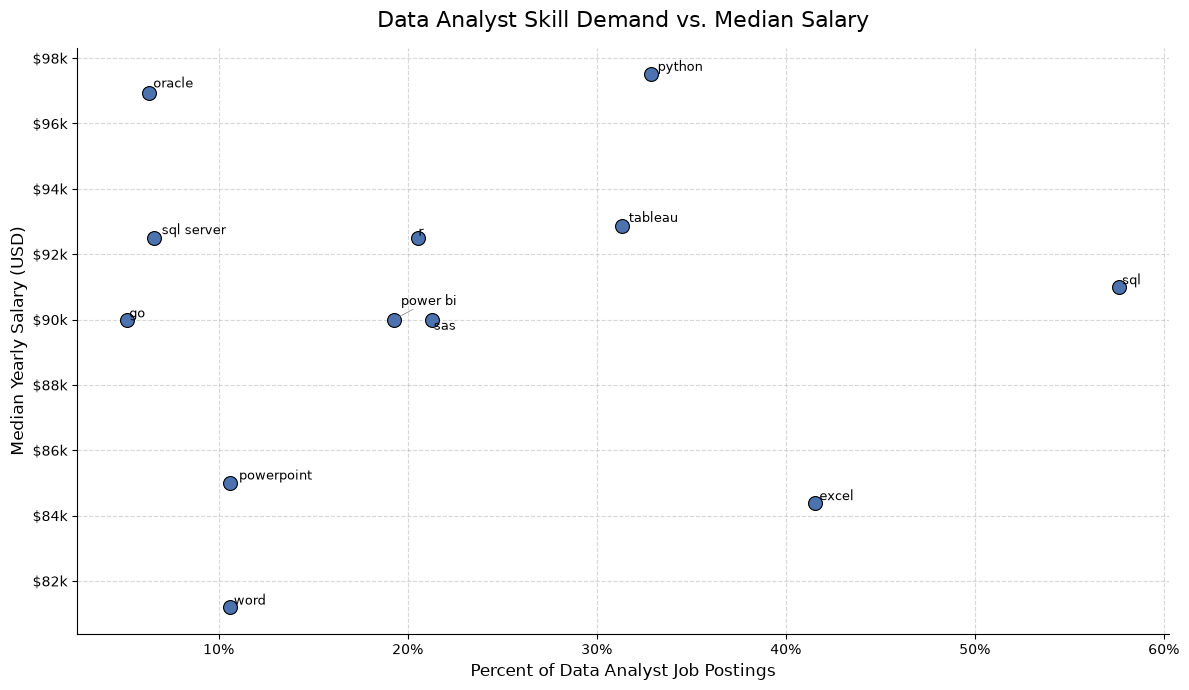

In [16]:
from adjustText import adjust_text

fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
    data=df_skills_high_demand,
    x='skill_percent',
    y='median_salary',
    s=100,
    color='#4C72B0',
    edgecolor='black',
    ax=ax
)

texts = [
    ax.text(
        row.skill_percent,
        row.median_salary,
        skill,
        fontsize=9
    )
    for skill, row in df_skills_high_demand.iterrows()
]
adjust_text(texts, ax=ax, arrowprops={'arrowstyle': '-', 'color': 'gray', 'lw': 0.5})

ax.set_title('Data Analyst Skill Demand vs. Median Salary', fontsize=16, pad=15)
ax.set_xlabel('Percent of Data Analyst Job Postings', fontsize=12)
ax.set_ylabel('Median Yearly Salary (USD)', fontsize=12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'${y / 1000:.0f}k'))

ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
sns.despine()
plt.tight_layout()
plt.show()

In [18]:
df_technology = df['job_type_skills'].copy()

df_technology = df_technology.drop_duplicates()

df_technology = df_technology.dropna()

technology_dict = {}

for row in df_technology:
    row_dict = ast.literal_eval(row) # converting string to dictionary
    for key, value in row_dict.items():
        if key in technology_dict:
            technology_dict[key] +=value
        else:
            technology_dict[key] =value

for key, value in technology_dict.items():
    technology_dict[key] = list(set(value))

technology_dict


{'analyst_tools': ['ms access',
  'spreadsheet',
  'ssis',
  'sap',
  'word',
  'looker',
  'outlook',
  'splunk',
  'spss',
  'power bi',
  'tableau',
  'powerpoint',
  'sheets',
  'dax',
  'microstrategy',
  'ssrs',
  'excel',
  'sharepoint',
  'alteryx',
  'sas',
  'cognos',
  'esquisse',
  'visio',
  'powerbi',
  'qlik',
  'msaccess',
  'nuix',
  'datarobot'],
 'programming': ['dart',
  'pascal',
  'typescript',
  'mongo',
  'ruby',
  'f#',
  'sql',
  'no-sql',
  'vba',
  'golang',
  'vb.net',
  'solidity',
  'clojure',
  'javascript',
  'powershell',
  'apl',
  'assembly',
  'html',
  'python',
  'haskell',
  'visualbasic',
  'c#',
  'perl',
  'c',
  'sass',
  'cobol',
  'objective-c',
  'java',
  'lua',
  'groovy',
  'erlang',
  'css',
  'crystal',
  'mongodb',
  'bash',
  'scala',
  'swift',
  'julia',
  'visual basic',
  'matlab',
  'go',
  'sas',
  'elixir',
  'lisp',
  'rust',
  'kotlin',
  'c++',
  'shell',
  'nosql',
  'php',
  'delphi',
  'fortran',
  'ocaml',
  'r',
  't-

In [19]:
df_technology = pd.DataFrame(list(technology_dict.items()), columns = ['technology', 'skills'])

df_technology = df_technology.explode('skills')

df_technology

,technology,skills
0,analyst_tools,ms access
0,analyst_tools,spreadsheet
0,analyst_tools,ssis
0,analyst_tools,sap
0,analyst_tools,word
...,...,...
9,sync,wire
9,sync,rocketchat
9,sync,slack
9,sync,unify


In [20]:
df_skills_high_demand.merge(df_technology, left_on = 'job_skills', right_on = 'skills')

,skill_count,median_salary,skill_percent,technology,skills
0,2508,91000.00,57.655172,programming,sql
1,1808,84392.00,41.563218,analyst_tools,excel
2,1431,97500.00,32.896552,programming,python
3,1364,92875.00,31.356322,analyst_tools,tableau
4,926,90000.00,21.287356,analyst_tools,sas
5,926,90000.00,21.287356,programming,sas
6,893,92500.00,20.528736,programming,r
7,838,90000.00,19.264368,analyst_tools,power bi
8,462,85000.00,10.620690,analyst_tools,powerpoint
9,461,81194.75,10.597701,analyst_tools,word


In [ ]:
df_skills_tech = (
    df_skills_high_demand.reset_index()
    .merge(df_technology, left_on='job_skills', right_on='skills', how='left')
    .drop_duplicates(subset=['job_skills', 'technology'])
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.scatterplot(
    data=df_skills_tech,
    x='skill_percent',
    y='median_salary',
    hue='technology',
    palette='tab10',
    s=100,
    edgecolor='black',
    ax=ax
)

texts = [
    ax.text(row.skill_percent, row.median_salary, row.job_skills, fontsize=9)
    for row in df_skills_tech.itertuples()
]
adjust_text(texts, ax=ax, arrowprops={'arrowstyle': '-', 'color': 'gray', 'lw': 0.5})

ax.set_title('Data Analyst Skill Demand vs. Median Salary', fontsize=16, pad=15)
ax.set_xlabel('Percent of Data Analyst Job Postings', fontsize=12)
ax.set_ylabel('Median Yearly Salary (USD)', fontsize=12)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'${y / 1000:.0f}k'))

ax.grid(True, linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.legend(title='Technology', bbox_to_anchor=(1.02, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()